# GlandSeg Interactive Script

## To do next:
1. Polish interactive script so that it is very clean and robust. --> Still need to clean code but now works fine.
2. Convert the interactive script to automatic script by removing visuals, merging cells, and looping through slides.
3. Finish memory efficient script, probably best done from automatic script.

In [1]:
##############
## INITIATE ##
##############

## Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

## Import modules
from f_wsi_reader import slide_path_to_tiles_at_coordinates
from f_wsi_reader import get_tile_map
from f_wsi_reader import read_slide
from f_wsi_reader import get_dimensions
from f_wsi_reader import apply_all_filters
from f_wsi_reader import apply_all_transforms
from f_wsi_reader import reassemble_tiles
from f_wsi_reader import select_patches_on_grid
from f_extract_objects import extract_object_pixels
from f_extract_objects import polish
from f_extract_objects import inlay_objects
from f_extract_objects import get_bounding_box_square

#
###

In [27]:
###########
## PATHS ##
###########

## Paths
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/SEGG/images/train/EU_37106_15_2K_HandE+-+2017-11-28+11.43.55_TissueTrain_(1.00,63062,11375,5880,10230)/reference/EU_37106_15_2K_HandE+-+2017-11-28+11.43.55_TissueTrain_(1.00,63062,11375,5880,10230).png']
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/PANDA/images/tiff/0a93d9a674e358ba32e4e2ec320aefc5.tiff'] # PANDA example 1
# wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/PANDA/images/tiff/0bfe4af623f6be66a82289e411320773.tiff'] # PANDA example 2
wsi_paths = ['/Volumes/SED/BDI/databases/RAW/datasets/TCGA/images/svs/TCGA-EJ-5509-01A_1.svs'] # TCGA
# wsi_paths = '/Volumes/SED/BDI/databases/RAW/datasets/ICGCC/images/svs/TB10.0575_V2_1.svs',

#
###

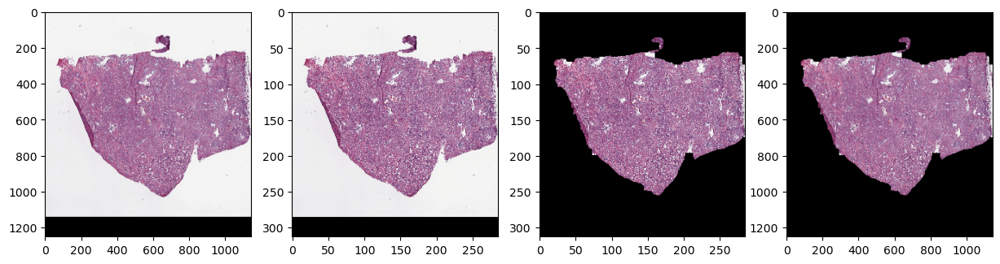

In [28]:
################## 
## GET TILE MAP ##
################## 

## Parameters
TILE_SIZE = 64
filter_low = 10
filter_high = 240
filter_std = 2
wsi_path = wsi_paths[0]

## Open slide
slide = read_slide(wsi_path)
slide_size = get_dimensions(slide)

## Get tile_map
thumbnail, tile_map, canvas_size = get_tile_map(slide, TILE_SIZE) # Canvas is a space containing the WSI.

def detect_tissue(tile_map):

## Extract coordinates of pixels in tile_map that contain tissue
mask_tissue = apply_all_filters(tile_map, low=filter_low, std=filter_std, high=filter_high)
mask_tissue = apply_all_transforms(mask_tissue)

## Get background
objects = extract_object_pixels(1-mask_tissue)

## Remove background
if objects != []:

    ## Get bacgkround mask
    background_tiles_coordinates = np.array(objects[np.argmax([len(object) for object in objects])])
    mask_background = np.zeros((mask_tissue.shape[0], mask_tissue.shape[1], 1))
    mask_background[background_tiles_coordinates[:,0], background_tiles_coordinates[:,1]] = 1
    
    ## Define not background mask
    mask = 1 - mask_background
    
    ## Erosion to reduce boundary
    kernel = np.ones((5, 5), np.uint8) # Adjust the kernel size if needed
    mask = cv2.erode(mask, kernel, iterations=1)
    
    ## Format
    mask = mask.astype(np.uint8)
    mask = mask.reshape(mask.shape[0], mask.shape[1], 1)

else:

    ## Otherwise use tissue mask
    mask = mask_tissue

## Get coordinates of tiles with tissue
tile_coordinates = (np.argwhere(mask[:,:,0] > 0) * TILE_SIZE).astype(int)
tile_coordinates = [[tile_coordinate[0], tile_coordinate[1]] for tile_coordinate in tile_coordinates] # (x: H, y: W)

## Compute slide-level tissue mask
tile_map_masked = tile_map * mask
thumbnail_masked = thumbnail * cv2.resize(mask, (thumbnail.shape[1], thumbnail.shape[0]), cv2.INTER_LINEAR)[:,:,None] # (H, W)

## Compute slide-level tissue mask
tissue_mask = cv2.resize(mask, (canvas_size[1], canvas_size[0]), cv2.INTER_LINEAR)[:,:,None] # (H, W)

## Visualise mask
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
axes[0].imshow(thumbnail)
axes[1].imshow(tile_map)
axes[2].imshow(tile_map_masked)
axes[3].imshow(thumbnail_masked)
plt.show()
plt.close()

#
###

Number of patches: 704


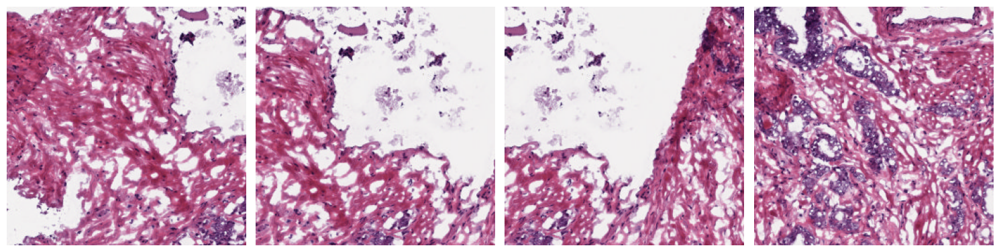

In [30]:
################################
## PATCH EXTRACTION FOR MODEL ##
################################

## Parameters
level = 1
tile_size_model = 1024

## Adjust tile size based on downsampling
ds = 1
if level > 0: 
    ds = 4 * level
tile_size_model = int(tile_size_model/ds)

## Remove patches too close to the edges
tile_coordinates_ds = []
for tile_coordinates_ in tile_coordinates:
    coords_0_lo = tile_coordinates_[0] + int(tile_size/2) - int(tile_size_model/2)
    coords_0_hi = tile_coordinates_[0] + int(tile_size/2) + int(tile_size_model/2)
    coords_1_lo = tile_coordinates_[1] + int(tile_size/2) - int(tile_size_model/2)
    coords_1_hi = tile_coordinates_[1] + int(tile_size/2) + int(tile_size_model/2)
    if (coords_0_lo > 0) & (coords_0_hi < canvas_size[0]) & (coords_1_lo > 0) & (coords_1_hi < canvas_size[1]):
        tile_coordinates_ds += [[coords_0_lo, coords_1_lo]]

## Get patches closest to grid points
tile_coordinates_ds = select_patches_on_grid(tile_coordinates_ds, grid_spacing=512)
print(f'Number of patches: {len(tile_coordinates_ds)}')

## Load patches from the dataset
patches = slide_path_to_tiles_at_coordinates(wsi_path, tile_coordinates_ds, tile_size_model, level) # [dataset[i] for i in range(min(num_patches_to_display, len(dataset)))]

## Display the patches
num_patches_to_display = 4
fig, axes = plt.subplots(1, num_patches_to_display, figsize=(15, 5))
for i, ax in enumerate(axes.flat):
    if i < len(patches):
        ax.imshow(patches[i])
        ax.axis('off')
    else:
        ax.axis('off') # Hide unused subplots if any
plt.tight_layout()
plt.show()

#
###

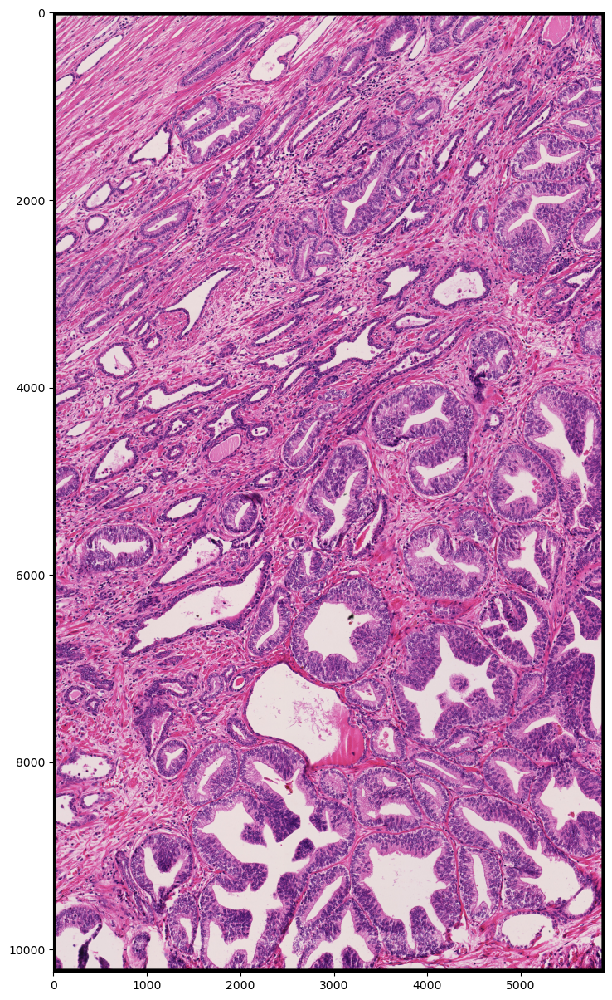

In [19]:
######################
## REASSEMBLE IMAGE ##
######################

## Reassemble image
img = reassemble_tiles(patches, tile_coordinates_ds, canvas_size[0], canvas_size[1])

## Mask
img = img * tissue_mask

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15, 15))
axes.imshow(img)
plt.show()
plt.close()

#
###

In [20]:
#####################################
## FUNCTIONS FOR MODEL APPLICATION ##
#####################################

## numpy_to_device
## Goal:
## Format numpy array for model.
## Inputs:
## X (list of numpy arrays): Input array for the model (B, H, W, C).
## Outputs:
## tensors (list of torch tensors): Output tensor for model (B, C, H, W).
def numpy_to_device(X):
    tensors = []
    for x in X:        
        x = cv2.resize(x, (1024, 1024))
        x = torch.tensor(x)        
        x = x.swapaxes(2, 1).swapaxes(1, 0) # (H, W, C) --> (C, H, W)
        x = x.float()
        x = x[None, :, :, :] # (C, H, W) --> (B=1, C, H, W)
        x = x.to(device)
        tensors += [x]        
    return tensors

## device_to_numpy
## Goal: 
## Format tensor on device back to numpy array.
## Inputs:
## X (list of torch tensors): List of torch tensors predictions from the model (B, C, H, W).
## Outputs:
## images (list of numpy arrays): List of images produced by the model after re-formatting (B, H, W, C).
def device_to_numpy(X):
    images = []
    for x in X:
        x = x.cpu().numpy()
        x = x.swapaxes(0, 1).swapaxes(1, 2)    
        x = x.astype('uint8')
        x = cv2.resize(x, (tile_size_model, tile_size_model))
        images += [x]        
    return images

#
###

In [21]:
#################
## APPLY MODEL ##
#################

## Parameters
device = "mps"

## Models specifications
# from f_model import UNet as Model
# pt_model_in = 'models/r10_3.pth'
# num_classes = 4
from f_model_transformer import UNetTransformer as Model
pt_model_in = 'models/TransUNet_V2_0.pth'
num_classes = 3

## Load model
print(f"Using {device} device")
model = Model(n_classes=num_classes).to(device)
if os.path.exists(pt_model_in):
    model.load_state_dict(torch.load(pt_model_in))
    print("Loaded model")

## Apply to all tiles
preds = []
X = numpy_to_device(patches)
with torch.no_grad():
    for x in X:                
        Yhat = model(x)        
        Yhat = torch.sigmoid(Yhat) * 255 # Logits to probabilities to [0, 255]
        Yhat = device_to_numpy(Yhat)[0] # Only for single patch
        Yhat = np.argmax(Yhat, axis=2).reshape(Yhat.shape[0], Yhat.shape[1], 1) # Only for multiple classes
        preds += [Yhat]

#
###

Using mps device
Loaded model


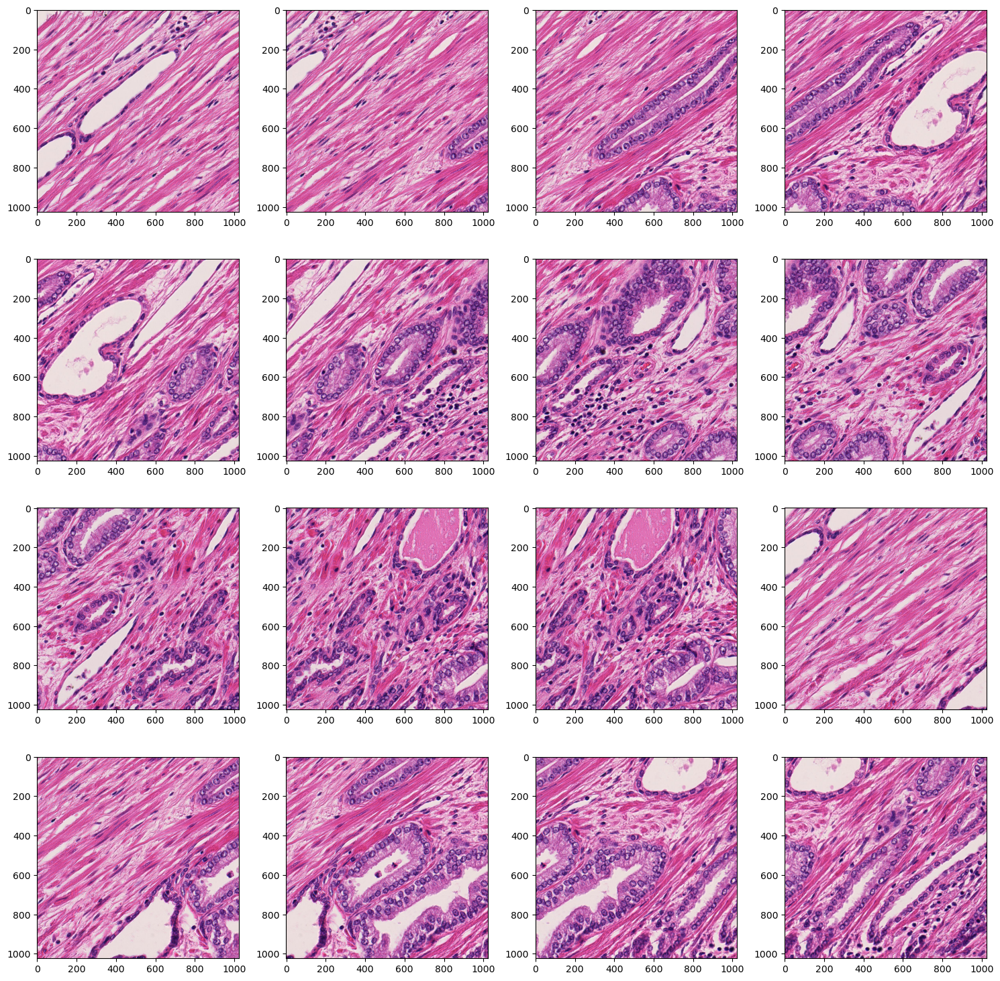

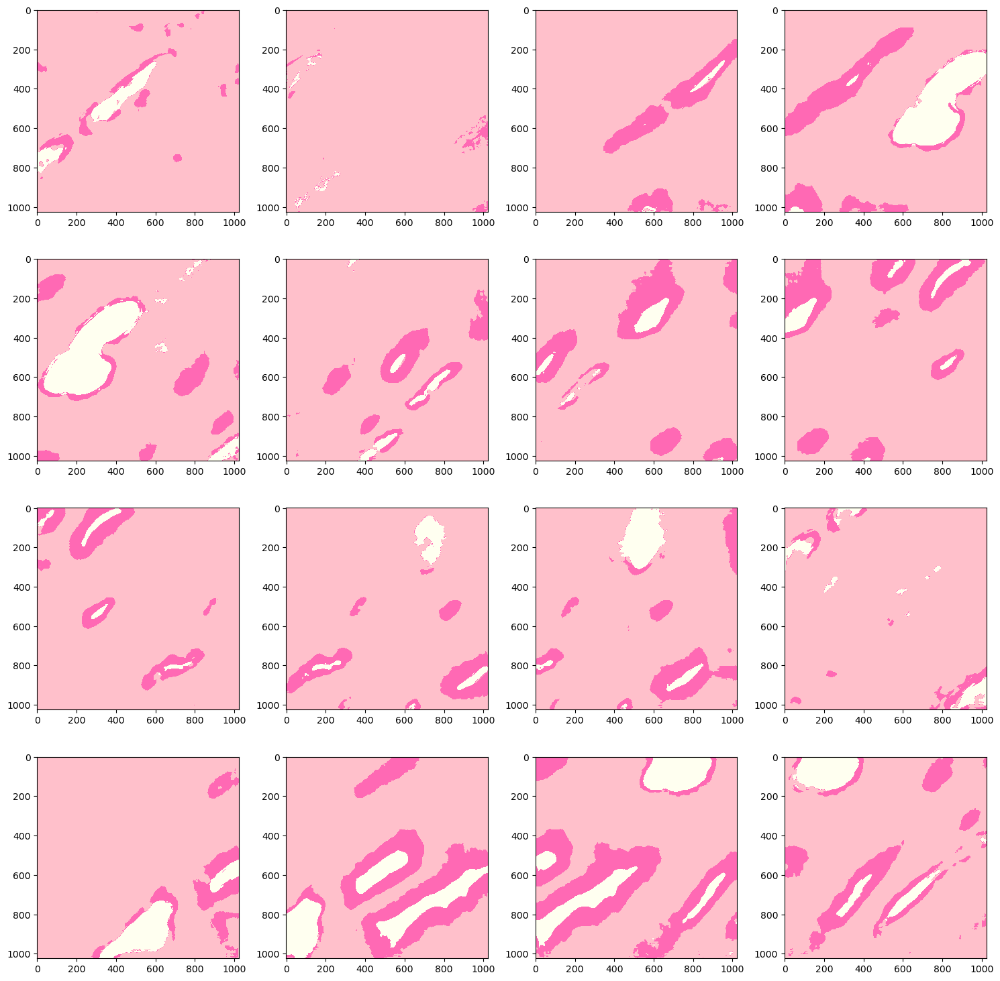

In [22]:
###########################
## VISUALISE PREDICTIONS ##
###########################

## Parameters
theme = 'H&E'

## Graphical parameters
if theme == 'H&E':
    from matplotlib.colors import ListedColormap
    custom_cmap = ListedColormap(['pink', 'hotpink', 'ivory'])
else:
    custom_cmap = 'gist_gray'

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(patches[k], cmap=custom_cmap)
        k += 1
plt.tight_layout()
plt.show()
plt.close()

## Visualise prediction patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]
        axis.imshow(preds[k], cmap=custom_cmap)        
        k += 1
plt.tight_layout()
plt.show()
plt.close()

#
###

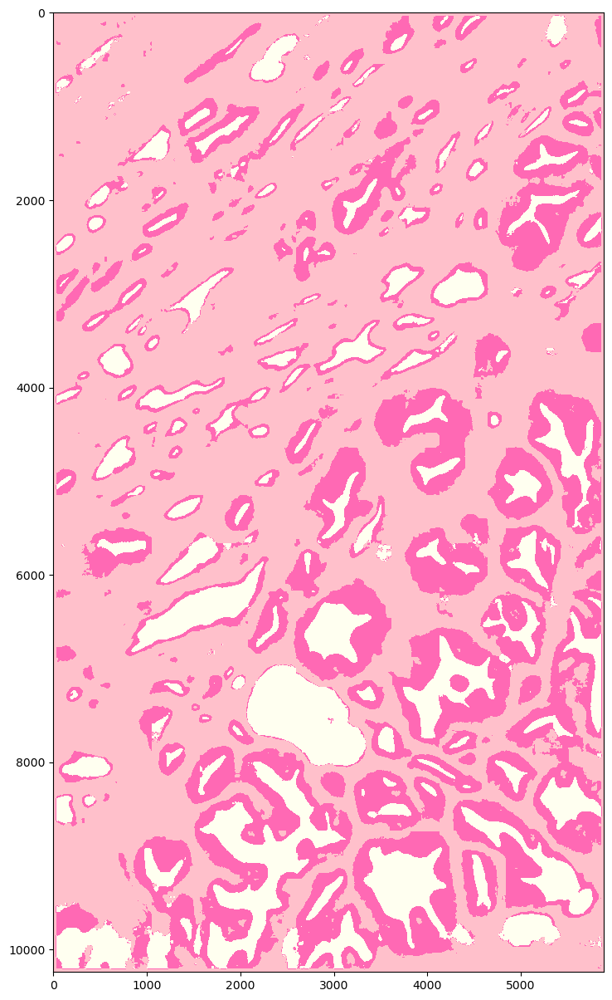

In [23]:
############################
## REASSEMBLE PREDICTIONS ##
############################

## Assemble predictions
mask = reassemble_tiles(preds, tile_coordinates_ds, canvas_size[0], canvas_size[1])
mask = mask[:,:,0].reshape(mask.shape[0], mask.shape[1], 1) * tissue_mask # For black and white theme

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15, 15))
if custom_cmap != 'gist_gray':
    axes.imshow(mask + (1 - tissue_mask) * 2, cmap=custom_cmap)
else:
    axes.imshow(mask, cmap=custom_cmap)
plt.show()
plt.close()

#
###

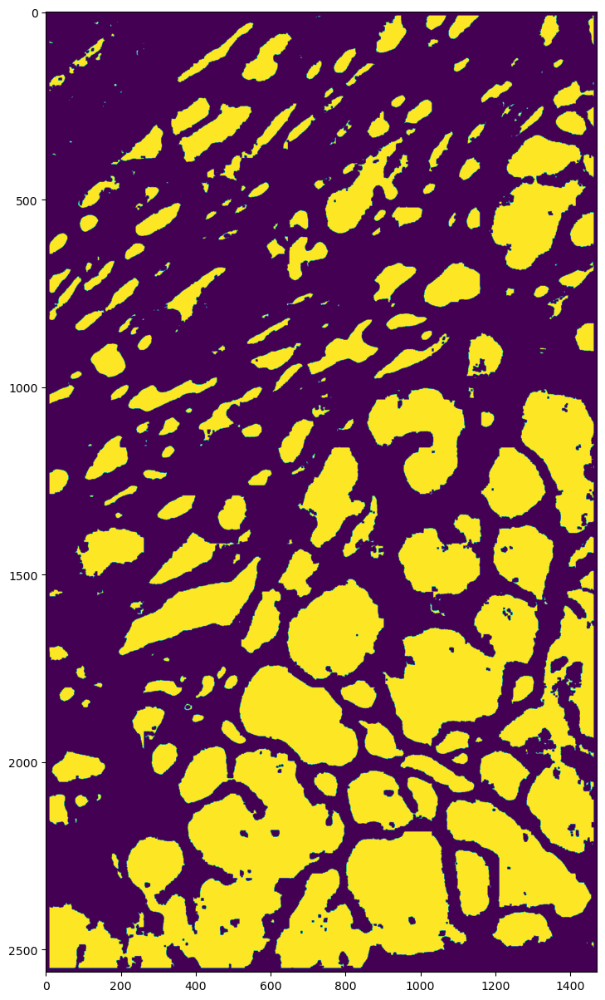

In [24]:
#################
## POLISH MASK ##
#################

## Downscale factor
downsample_extraction = 4
num_polish = 1

## Binarise mask
mask_bin = ((mask > 0)*1).astype('uint8')
mask_bin = cv2.resize(mask_bin, (int(mask_bin.shape[1]/downsample_extraction), int(mask_bin.shape[0]/downsample_extraction)))
mask_bin = mask_bin[:,:,None]

## Polish mask
for i in range(num_polish):
    mask_bin = polish(mask_bin)    

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(mask_bin)
plt.show()
plt.close()

#
###

Number of glands: 335


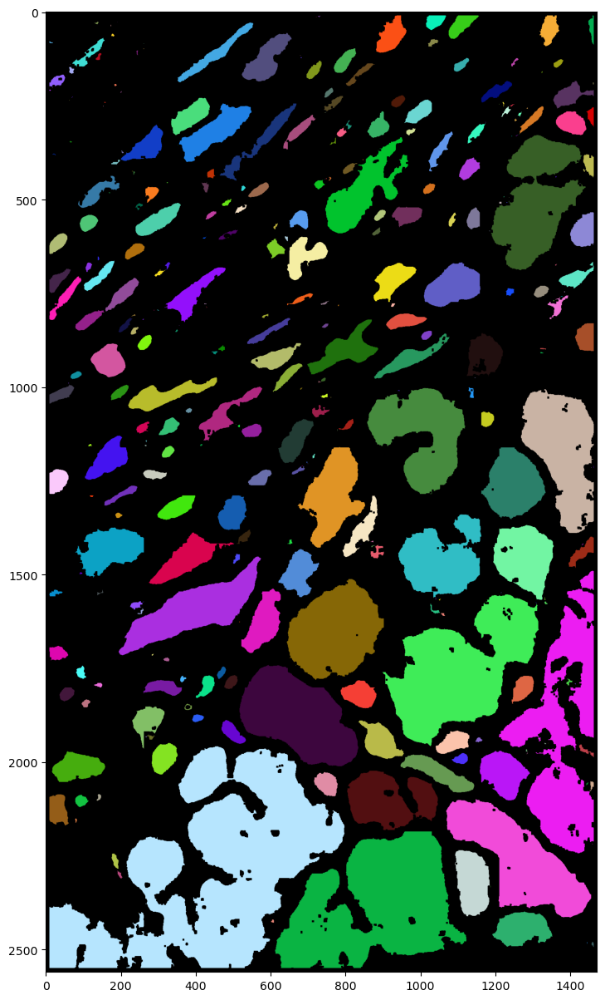

In [25]:
#####################
## EXTRACT OBJECTS ##
#####################

## Get objects
gland_coords = extract_object_pixels(mask_bin)
print(f'Number of glands: {len(gland_coords)}')

## Rescale coordinates to original size
rescaled_gland_coords = [coords * downsample_extraction for coords in gland_coords]

## Visualise objects
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(inlay_objects(mask_bin, gland_coords))
plt.show()
plt.close()

#
###

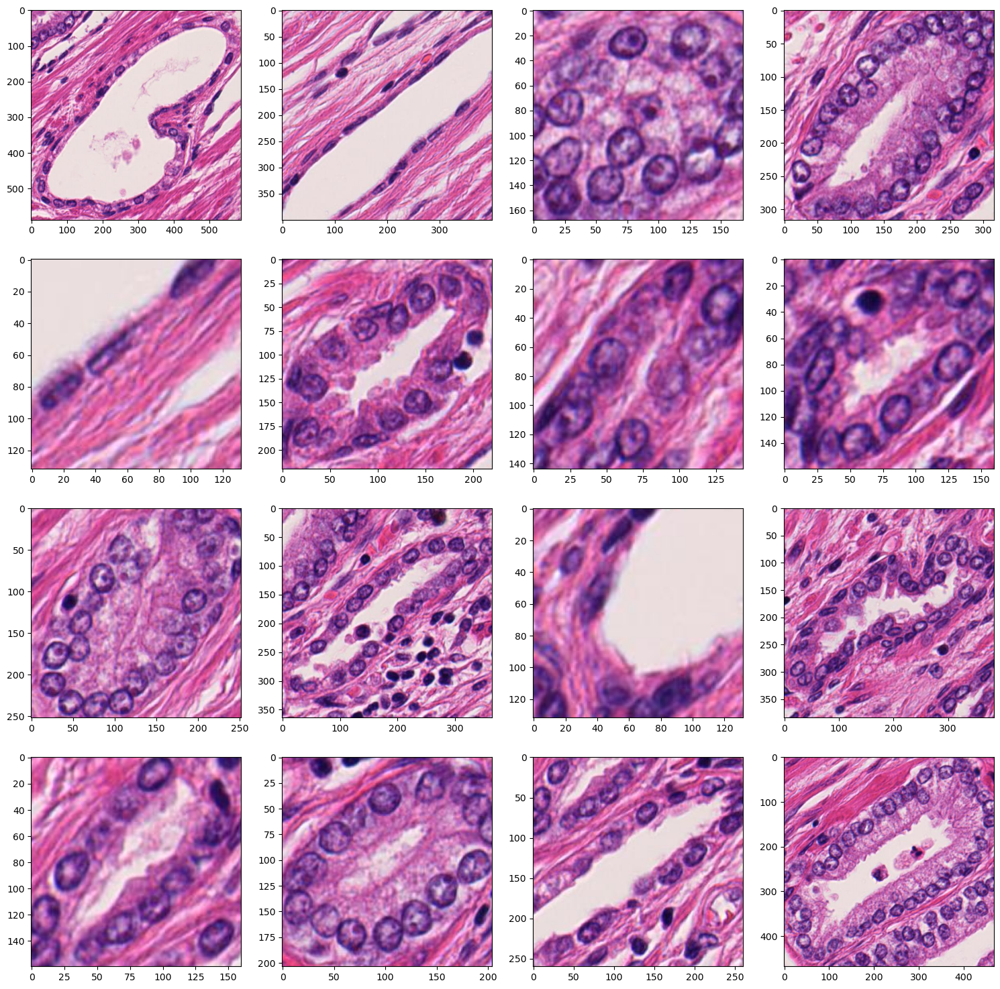

In [26]:
##################
## SAVE OBJECTS ##
##################

## Parameters
dxy = 30 # Added distance around bounding box (in pixels)
threshold_min = 100 # Minimum surface area of objects (in spixels)
threshold_max = 2000 * 100 # Maximum surface area of objects (in spixels)
prop_border = 0.01 # Maximum proportion of border pixels in image (proportion)
output_folder = '/Users/willembonnaffe/Desktop/extracted_objects_11' # Path where the gland images should be saved

## Paths
os.makedirs(output_folder, exist_ok=True)

## Extract and save each object
objects = []
for i, coords in enumerate(rescaled_gland_coords):

    ## Discard small objects
    if (len(coords) > threshold_min) & (len(coords) < threshold_max):
        
        ## Get bounding box of the object
        x_min, y_min, x_max, y_max = get_bounding_box_square(coords)
    
        ## Get object
        object_img = img[(y_min - dxy):(y_max + dxy), (x_min - dxy):(x_max + dxy)]

        ## Check size
        if (object_img.shape[0] > 0) & (object_img.shape[1] > 0):

            ## Check colour
            object_img = cv2.cvtColor(object_img, cv2.COLOR_BGR2RGB)    
            if (object_img.mean(2) < 10).sum()/(object_img.shape[0] * object_img.shape[1]) < prop_border:    
        
                ## Save the object image
                objects += [object_img]
                object_filename = os.path.join(output_folder, f'{os.path.basename(wsi_path)}_object_{i}.png')
                cv2.imwrite(object_filename, object_img)

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(cv2.cvtColor(objects[k], cv2.COLOR_BGR2RGB))
        k += 1
plt.tight_layout()
plt.show()
plt.close()

#
###